# 07 Final strategy: historical backtest (2012-08-01 to 2026-09-30)

**Final strategy = V2 (US, 30% vol target) + Singapore sleeve (ES3 GARCH + A35).**

- **Funding:** 90% to the US account and 10% to the Singapore account on 2012-08-01. After that each account trades only its own assets with its own cash. **Threshold rule:** if the Singapore share leaves 10% ± 1pt at a close, the Singapore account is reset to 10% of total value at the next date when both markets have a valid opening; otherwise there are no transfers. Transfers are listed in `final_historical_transfers.csv`.
- **Execution:** each account rebalances daily at its own next valid opening price, using the latest signal from an earlier date. A missing opening price means no trade that day. Carried prices are used for valuation only, never for fills.
- **Currency:** the Singapore account holds SGD; trades and fees are booked in SGD. NAV is translated to USD with the latest closing USD/SGD.
- **Periods:** IS and OOS are two windows of the same continuous account (no reset at 2020-01-01). Dates come from 00_engine.

All accounting lives in `portfolio_accounting.py`. Run after 03 → 02 → 05 → 06.

**Outputs:** `results/tables/final_metrics.csv` (the table to quote for final performance), `final_daily_accounts.csv`, `final_historical_trades.csv`, `final_equity_history.csv`, `final_diversification.csv`, `final_sharpe_bootstrap.csv`, and `results/figures/final_*.png`. The October live window is a separate account (08) and must not be appended to this equity curve.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / 'pipeline/00_engine.ipynb').is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import portfolio_accounting as pa

TABLE_DIR, SIGNAL_DIR, FIG_DIR = [ROOT / 'results' / s for s in ('tables','signals','figures')]
FINAL_NAME = 'Final V2 + Singapore (90/10 start; ±1pt threshold)'
DRIFT_NAME = 'Final V2 + Singapore (90/10 start; no rebalance)'

REBALANCE_BAND = 0.01

def sleeve_equity(weights, market, timeline, capital=1.0, rebalance='daily'):
    return pa.run_sleeve(market,weights,timeline,capital,rebalance)


def main(csv_path=None, n_boot=2000, save=True):
    us, sg = pa.load_markets(csv_path)
    w_v2, w_sg = pa.strategy_weights('v2')
    w_v0, _ = pa.strategy_weights('v0')
    timeline = pa.common_timeline((us,sg),pa.HISTORICAL_START)
    start = pa.HISTORICAL_START
    portfolio = pa.run_portfolio(us, sg, w_v2, w_sg, start, capital=1.0, rebalance_band=REBALANCE_BAND)
    v0_portfolio = pa.run_portfolio(us, sg, w_v0, w_sg, start, capital=1.0, rebalance_band=REBALANCE_BAND)
    drift = pa.run_portfolio(us, sg, w_v2, w_sg, start, capital=1.0)
    pure_v2 = sleeve_equity(w_v2,us,timeline)
    pure_v0 = sleeve_equity(w_v0,us,timeline)
    pure_sg = sleeve_equity(w_sg,sg,timeline)
    # Comparators enter using actual source openings and include entry fees.
    benchmarks = {}
    for ticker, market in [('SPY',us),('ES3',sg)]:
        w = pd.DataFrame({ticker:1.0},index=market.closes.index)
        benchmarks['Buy and hold '+ticker] = sleeve_equity(w,market,timeline,rebalance='buy_hold')
    curves = {
        FINAL_NAME:portfolio['daily'].equity,
        DRIFT_NAME:drift['daily'].equity,
        'V2 30% (US-only)':pure_v2['daily'].equity,
        'V0 + Singapore (initial 90/10)':v0_portfolio['daily'].equity,
        'V0 (US-only)':pure_v0['daily'].equity,
        'Singapore sleeve (ES3 GARCH + A35)':pure_sg['daily'].equity,
        **{n:r['daily'].equity for n,r in benchmarks.items()}}
    daily_map = {FINAL_NAME:portfolio['daily'],
        DRIFT_NAME:drift['daily'],
        'V2 30% (US-only)':pure_v2['daily'],
        'V0 + Singapore (initial 90/10)':v0_portfolio['daily'],
        'V0 (US-only)':pure_v0['daily'],
        'Singapore sleeve (ES3 GARCH + A35)':pure_sg['daily'],
        **{n:r['daily'] for n,r in benchmarks.items()}}
    rows=[]
    for name,eq in curves.items():
        for label,a,b in pa.PERIODS:
            count=len(eq.loc[a:b])
            if count<30:continue
            daily=daily_map[name]
            if 'traded_notional_usd' in daily:
                turn=(daily.traded_notional_usd / daily.equity.shift(1)).fillna(0)
            else:turn=daily.turnover
            rows.append({'Strategy':name,'Period':label,**pa.ENGINE['fmt'](pa.performance(eq,a,b)),
                         'Observations':count,'Annualized_turnover':round(float(turn.loc[a:b].sum()*252/count),2)})
    metrics=pd.DataFrame(rows)
    returns=pd.DataFrame(curves).pct_change(fill_method=None)
    div=[]
    for label,a,b in pa.PERIODS:
        r=returns.loc[a:b,['V2 30% (US-only)','Singapore sleeve (ES3 GARCH + A35)']].dropna()
        x,y=r.iloc[:,0],r.iloc[:,1];worst=x<=x.quantile(.05)
        div.append({'Period':label,'Daily return correlation':x.corr(y),
                    'US worst 5% days: US average return':x[worst].mean(),
                    'US worst 5% days: SG average return':y[worst].mean()})
    diversification=pd.DataFrame(div).set_index('Period')
    sti=pa.load_definitions('03_sti_garch')
    boots=[];labels=[]
    for other in ['V2 30% (US-only)','V0 (US-only)']:
        r=returns.loc[pa.ENGINE['OOS_START']:pa.ENGINE['OOS_END'],[FINAL_NAME,other]].dropna()
        boots.append(sti['block_bootstrap_sharpe_diff'](r.iloc[:,0].values,r.iloc[:,1].values,n_boot=n_boot))
        labels.append('Final vs '+other)
    bootstrap=pd.DataFrame(boots,index=labels)
    latest=pa.latest_targets(portfolio)
    display(metrics);display(diversification.round(4));display(bootstrap.round(4));display(latest)
    print(f'Initial funding: US 90%, Singapore 10%. Threshold +/-{REBALANCE_BAND:.0%}: {len(portfolio["transfers"])} transfers over the full history.')
    print('Latest sleeve shares:',portfolio['daily'][['US_sleeve_pct','SG_sleeve_pct']].tail(1).to_dict('records'))
    figs={}
    fig,ax=plt.subplots(figsize=(11,4.8))
    for name in [FINAL_NAME,'V2 30% (US-only)','V0 (US-only)','Singapore sleeve (ES3 GARCH + A35)']:
        e=curves[name].loc[:pa.ENGINE['OOS_END']]
        ax.plot(e.index,e/e.iloc[0],label=name)
    ax.set_yscale('log');ax.set_title('Historical equity through '+pa.ENGINE['OOS_END']);ax.legend(fontsize=7)
    fig.tight_layout();figs['final_equity']=fig
    fig,ax=plt.subplots(figsize=(11,3.8))
    for name in [FINAL_NAME,'V2 30% (US-only)','V0 (US-only)']:
        e=curves[name].loc[:pa.ENGINE['OOS_END']]
        ax.plot(e.index,(e/e.cummax()-1)*100,label=name)
    ax.set_ylabel('Drawdown (%)');ax.legend(fontsize=7);fig.tight_layout();figs['final_drawdown']=fig
    fig,ax=plt.subplots(figsize=(11,3.8))
    actual=portfolio['daily'].filter(regex='_pct$').drop(columns=['cash_pct','US_sleeve_pct','SG_sleeve_pct'])
    actual=actual.loc[:pa.ENGINE['OOS_END']]
    ax.stackplot(actual.index,*[actual[c] for c in actual],labels=[c.removesuffix('_pct') for c in actual])
    ax.set_ylim(0,1);ax.set_title('Actual asset weights; 90/10 start, SG reset when share leaves 10% +/- 1pt')
    ax.legend(loc='upper left',bbox_to_anchor=(1.01,1),fontsize=7);fig.tight_layout();figs['final_weights']=fig
    fig,ax=plt.subplots(figsize=(11,3.8))
    portfolio['daily'][['US_sleeve_pct','SG_sleeve_pct']].loc[:pa.ENGINE['OOS_END']].plot(ax=ax)
    ax.axhline(0.10-REBALANCE_BAND,ls=':',c='grey');ax.axhline(0.10+REBALANCE_BAND,ls=':',c='grey')
    ax.set_ylim(0,1);ax.set_title('Sleeve shares; SG reset to 10% when outside the band');fig.tight_layout();figs['final_sleeve_shares']=fig
    if save:
        for p in [TABLE_DIR,SIGNAL_DIR,FIG_DIR]:p.mkdir(parents=True,exist_ok=True)
        metrics.to_csv(TABLE_DIR/'final_metrics.csv',index=False,encoding='utf-8-sig')
        diversification.to_csv(TABLE_DIR/'final_diversification.csv',encoding='utf-8-sig')
        bootstrap.to_csv(TABLE_DIR/'final_sharpe_bootstrap.csv',encoding='utf-8-sig')
        pd.DataFrame(curves).to_csv(TABLE_DIR/'final_equity_history.csv',encoding='utf-8-sig')
        portfolio['daily'].to_csv(TABLE_DIR/'final_daily_accounts.csv',encoding='utf-8-sig')
        portfolio['trades'].to_csv(TABLE_DIR/'final_historical_trades.csv',index=False,encoding='utf-8-sig')
        portfolio['transfers'].to_csv(TABLE_DIR/'final_historical_transfers.csv',index=False,encoding='utf-8-sig')
        for name,f in figs.items():f.savefig(FIG_DIR/(name+'.png'),dpi=150,bbox_inches='tight')
    plt.show()
    return {'portfolio':portfolio,'curves':curves,'metrics':metrics,'latest':latest,'figures':figs}


,Strategy,Period,CAGR,Vol,Sharpe,Sortino,MDD,Calmar,Observations,Annualized_turnover
0,Final V2 + Singapore (90/10 start; ±1pt thresh...,IS,0.279,0.260,1.056,1.505,-0.392,0.713,1915,51.58
1,Final V2 + Singapore (90/10 start; ±1pt thresh...,OOS,0.435,0.268,1.450,2.135,-0.240,1.817,1742,50.14
2,Final V2 + Singapore (90/10 start; ±1pt thresh...,OOS ex-2020,0.335,0.260,1.215,1.785,-0.240,1.400,1484,48.92
3,Final V2 + Singapore (90/10 start; no rebalance),IS,0.290,0.275,1.043,1.486,-0.414,0.701,1915,54.83
4,Final V2 + Singapore (90/10 start; no rebalance),OOS,0.464,0.295,1.408,2.074,-0.268,1.731,1742,54.98
5,Final V2 + Singapore (90/10 start; no rebalance),OOS ex-2020,0.350,0.287,1.165,1.711,-0.268,1.308,1484,53.72
6,V2 30% (US-only),IS,0.305,0.286,1.052,1.503,-0.419,0.729,1915,57.01
7,V2 30% (US-only),OOS,0.467,0.297,1.409,2.075,-0.270,1.731,1742,55.31
8,V2 30% (US-only),OOS ex-2020,0.352,0.289,1.164,1.709,-0.270,1.303,1484,53.99
9,V0 + Singapore (initial 90/10),IS,0.470,0.391,1.154,1.774,-0.566,0.830,1915,53.52


,Daily return correlation,US worst 5% days: US average return,US worst 5% days: SG average return
Period,,,
IS,0.1470,-0.0437,-0.0040
OOS,0.0186,-0.0427,0.0003
OOS ex-2020,0.0125,-0.0408,0.0008


,Sharpe (strategy),Sharpe (comparator),Difference,95% CI lower,95% CI upper,p-value
Final vs V2 30% (US-only),1.4504,1.4091,0.0413,0.0028,0.0848,0.0485
Final vs V0 (US-only),1.4504,1.5738,-0.1235,-0.4795,0.2442,0.5045


,sleeve,signal_date,target_within_sleeve,current_total_weight,current_sleeve_share,indicative_total_weight,execution_rule
ticker,,,,,,,
TQQQ,US,2026-10-16,0.546370,0.485317,0.899202,0.491297,Next valid local source opening; refresh prior...
UVXY,US,2026-10-16,0.000000,0.000000,0.899202,0.000000,Next valid local source opening; refresh prior...
TECL,US,2026-10-16,0.000000,0.000000,0.899202,0.000000,Next valid local source opening; refresh prior...
SPXL,US,2026-10-16,0.000000,0.000000,0.899202,0.000000,Next valid local source opening; refresh prior...
TECS,US,2026-10-16,0.000000,0.000000,0.899202,0.000000,Next valid local source opening; refresh prior...
BSV,US,2026-10-16,0.453630,0.413885,0.899202,0.407905,Next valid local source opening; refresh prior...
ES3,Singapore,2026-10-15,0.692423,0.069623,0.100798,0.069795,Next valid local source opening; refresh prior...
A35,Singapore,2026-10-15,0.307577,0.031175,0.100798,0.031003,Next valid local source opening; refresh prior...


Initial funding: US 90%, Singapore 10%. Threshold +/-1%: 84 transfers over the full history.
Latest sleeve shares: [{'US_sleeve_pct': 0.8992017035439946, 'SG_sleeve_pct': 0.10079829645600535}]


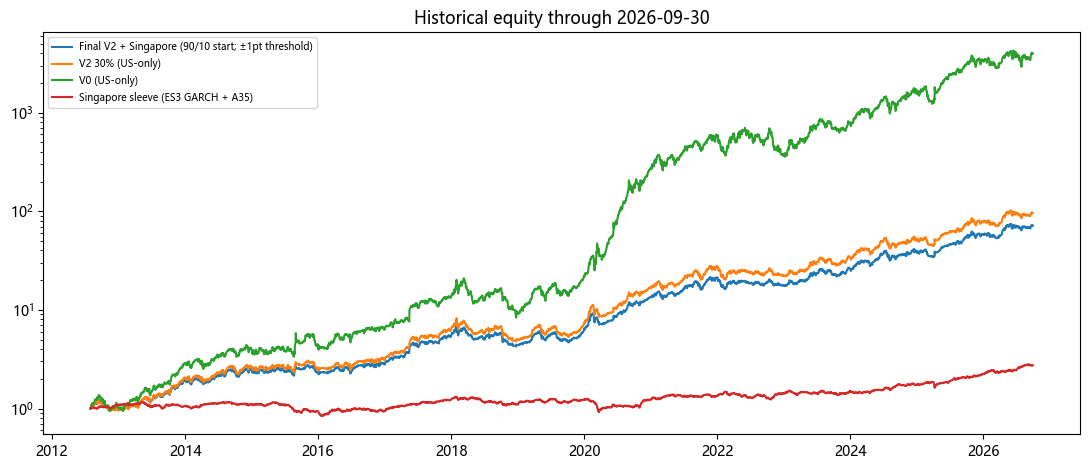

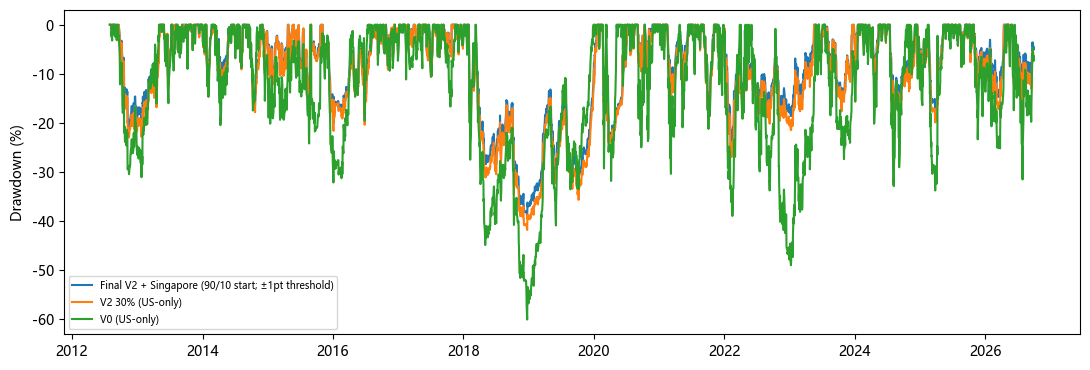

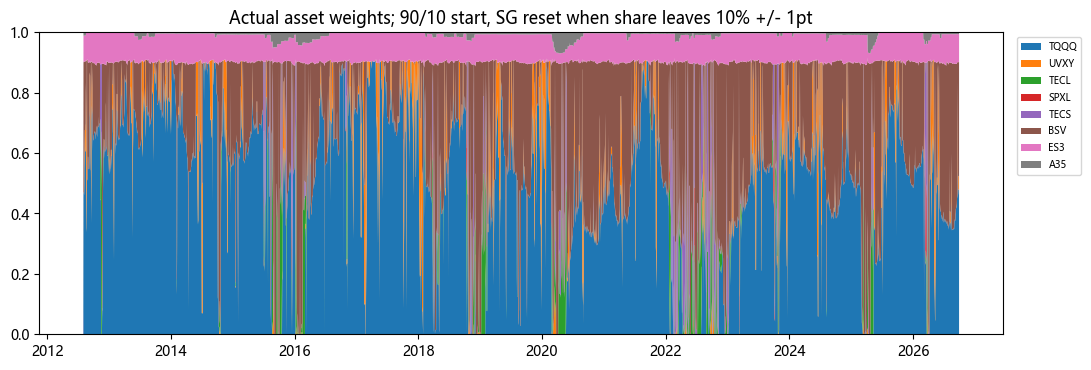

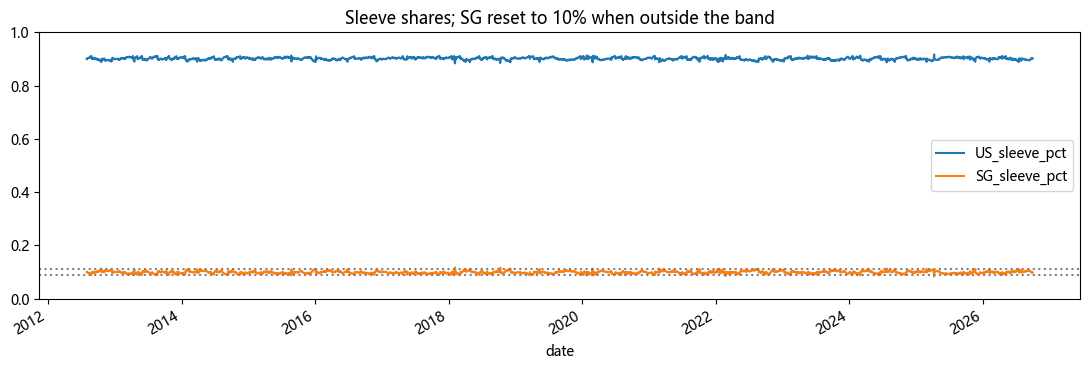

In [2]:
# Run All after 03 -> 02 -> 05 -> 06 have produced their signal files.
results_final = main(save=True)
